# Churn risk: discrimination, calibration and decision sensitivity

**Project 1 · October 26, 2026 · Himanshu Jadaun**

An applied Data Science study using supervised ML on observed public telecom records. This notebook explains and audits the completed experiment. The full nested training workflow is `python run_study.py`; this walkthrough does not repeatedly refit models or choose candidates using an already-inspected holdout.

**Question:** can defensible probabilities and a useful review ranking be learned from this source? A positive answer does not imply that a retention offer would work.

**New technique:** nested group-aware probability calibration. See the builder’s guide for the full fold-by-fold derivation.

In [1]:
import json
from pathlib import Path
import numpy as np
import pandas as pd
from IPython.display import display, Image
from sklearn.metrics import average_precision_score, brier_score_loss
from study import load_data, CONSERVATIVE
HERE = Path.cwd()
assert (HERE / 'study.py').exists(), 'Execute with this project as the working directory.'
result = json.loads((HERE / 'results/metrics.json').read_text())
X, y, audit = load_data()
display(pd.Series(audit, name='Source audit'))

source                                     https://archive.ics.uci.edu/dataset/563/irania...
download                                   https://archive.ics.uci.edu/static/public/563/...
license                                                                            CC BY 4.0
source_zip_sha256                          696c3a1812267980751f30d19193a1b430ac4ad76172bb...
rows                                                                                    3150
predictors                                                                                13
churn_labels                                                                             495
nonchurn_labels                                                                         2655
churn_prevalence                                                                    0.157143
exact_repeated_rows                                                                      300
repeated_full_predictor_rows                                          

## 1. Establish what is real and what is missing

Source: [Iranian Churn, UCI 563](https://archive.ics.uci.edu/dataset/563/iranian+churn+dataset), DOI [10.24432/C5JW3Z](https://doi.org/10.24432/C5JW3Z), CC BY 4.0. This source describes a historical Iranian telecom sample, with months 1–9 predictors and month-twelve target state. There are no actual calendar dates for a rolling backtest and no treatment assignments.

The source bytes are hash-checked. No synthetic customers, dates or labels enter the analysis. `row_id` is source position; identical predictor profiles are not proven identical customers.

In [2]:
source = X.copy()
source['churn'] = y
display(source[CONSERVATIVE].describe().T[['count','mean','std','min','50%','max']])
display(source.groupby('complains').agg(records=('churn','size'), churn_labels=('churn','sum'), churn_fraction=('churn','mean')))
# This is an observational relationship, not the causal effect of complaining.
print('Repeated full rows:', audit['exact_repeated_rows'])
print('Conservative profiles with conflicting labels:', audit['conflicting_conservative_profile_groups'])

Repeated full rows: 300
Conservative profiles with conflicting labels: 22


,count,mean,std,min,50%,max
call_failure,3150.0,7.627937,7.263886,0.0,6.0,36.0
complains,3150.0,0.076508,0.265851,0.0,0.0,1.0
subscription_length,3150.0,32.541905,8.573482,3.0,35.0,47.0
charge_amount,3150.0,0.942857,1.521072,0.0,0.0,10.0
seconds_of_use,3150.0,4472.459683,4197.908687,0.0,2990.0,17090.0
frequency_of_use,3150.0,69.460635,57.413308,0.0,54.0,255.0
frequency_of_sms,3150.0,73.174921,112.237560,0.0,21.0,522.0
distinct_called_numbers,3150.0,23.509841,17.217337,0.0,21.0,97.0
age_group,3150.0,2.826032,0.892555,1.0,3.0,5.0
tariff_plan,3150.0,1.077778,0.267864,1.0,1.0,2.0


,records,churn_labels,churn_fraction
complains,,,
0,2909,295,0.101409
1,241,200,0.829876


## 2. Freeze the split before judging models

Group identical conservative predictor vectors across all boundaries. Five shuffled stratified group folds define the final holdout; the first fold is reserved. Three outer folds within development assess model candidates. Inside each outer-training portion, three calibration folds hold back calibration labels; inside each calibration-training portion, three grouped tuning folds fit pipelines and select parameters.

Primary models exclude Status and Customer Value pending operational verification. UCI says all predictors cover the first nine months; this conservative policy is not evidence of leakage. All-field models are sensitivity analyses, ineligible for primary selection.

In [3]:
splits = pd.read_csv(HERE / 'results/split_assignments.csv')
dev = splits.query("split == 'development'")
test = splits.query("split == 'test'")
assert not (set(dev.profile_group) & set(test.profile_group))
display(splits.groupby('split').agg(records=('row_id','size'), positives=('target','sum'), profiles=('profile_group','nunique')))
plan = json.loads((HERE / 'experiment_plan.json').read_text())
selection = json.loads((HERE / 'results/selection_locked_before_test.json').read_text())
print('Selected using development OOF Brier:', selection['selected'])
print('Final test row count:', len(test))

Selected using development OOF Brier: conservative_gradient_boosting
Final test row count: 639


,records,positives,profiles
split,,,
development,2511,392,2255
test,639,103,571


## 3. Reproduce the no-skill baseline

Predict the development prevalence for every held-out record. At threshold 0.5 this predicts no churn for everyone. Accuracy can look good while positive-class recall is zero. The baseline is fitted to development labels only.

In [4]:
pred = pd.read_csv(HERE / 'results/test_predictions.csv')
prior = y[dev.row_id].mean()
constant = np.full(len(pred), prior)
assert np.allclose(constant, pred.prior)
baseline = {'training_prior': prior, 'test_accuracy': np.mean((constant >= .5) == pred.target),
            'test_churn_recall': np.sum((constant >= .5) & (pred.target == 1)) / pred.target.sum(),
            'average_precision': average_precision_score(pred.target, constant),
            'brier': brier_score_loss(pred.target, constant)}
display(pd.Series(baseline))

training_prior       0.156113
test_accuracy        0.838811
test_churn_recall    0.000000
average_precision    0.161189
brier                0.135233
dtype: float64

## 4. Compare ranking and probability scores

Logistic regression is the simple comparator; histogram boosting tests nonlinear predictive structure. Preprocessing is fitted only inside its relevant training fold. AP is average precision, not trapezoidal PR area. Brier is mean squared probability error, not a pure calibration score.

The error bars resample whole held-out profiles 500 times. They condition on fitted models and this source sample, excluding training/source/market uncertainty. The paired Brier interval compares models on identical resamples.

,average_precision,roc_auc,brier,log_loss,accuracy_at_0_5
prior,0.161189,0.500000,0.135233,0.441734,0.838811
conservative_logistic,0.771665,0.930916,0.072674,0.246445,0.902973
conservative_gradient_boosting,0.929834,0.982430,0.037211,0.134661,0.940532
all_logistic,0.760789,0.932039,0.073718,0.246295,0.895149
all_gradient_boosting,0.941539,0.985020,0.035584,0.130680,0.949922


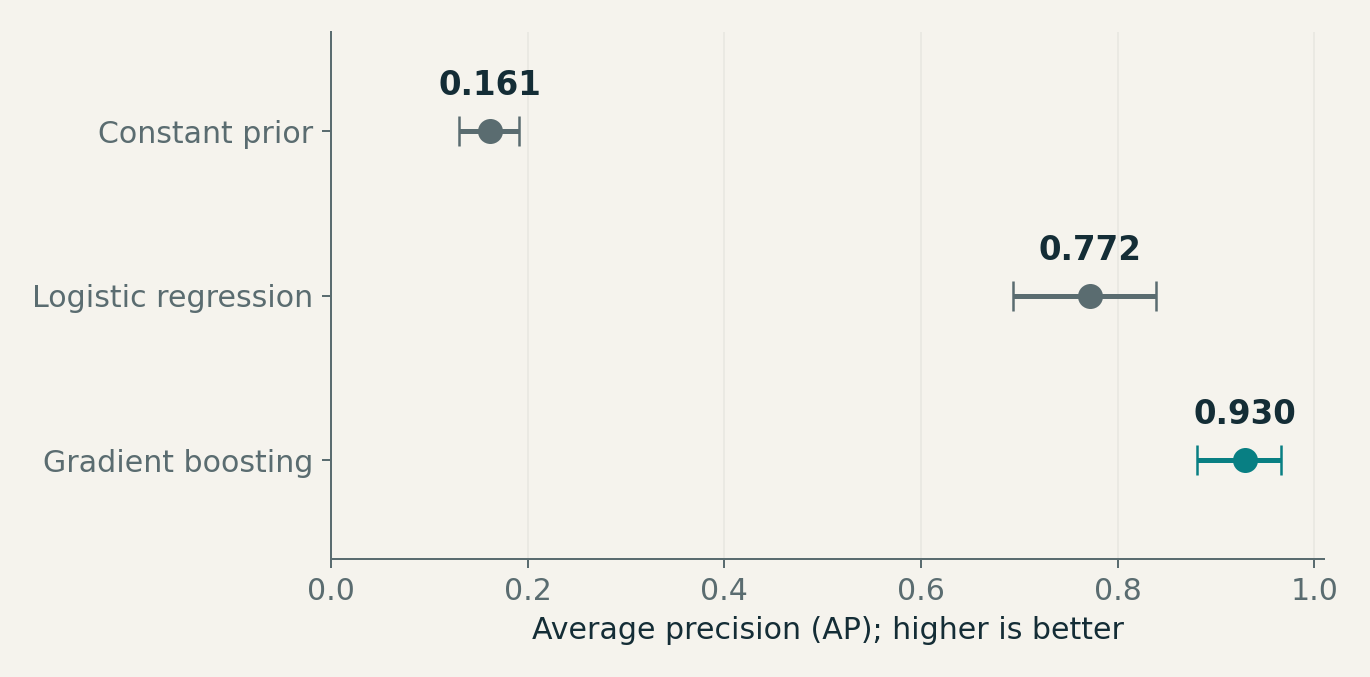

{'comparison': 'Conservative gradient boosting minus conservative logistic Brier',
 'low': -0.04918040077501591,
 'high': -0.021805320902658083,
 'interpretation': 'Negative favors boosting; interval conditional on fitted models and the held-out source sample'}

In [5]:
display(pd.DataFrame(result['test_metrics']).T)
selected = result['selected_model']
for name, values in result['test_metrics'].items():
    assert np.isclose(average_precision_score(pred.target, pred[name]), values['average_precision'])
    assert np.isclose(np.mean((pred[name] - pred.target) ** 2), values['brier'])
display(Image(filename=str(HERE / 'figures/02_average_precision.png')))
display(result['paired_brier_difference'])

## 5. Keep the calibration result even when it is negative

Compare the same base learners before/after sigmoid calibration. The matched raw ensemble slightly improves Brier and log loss here. No new winner is chosen after looking at the test set. The calibrated candidate remains primary; a future development-only experiment can compare calibration approaches.

The eight-bin reliability diagnostic includes sparse bins. Brier combines calibration and resolution; do not infer calibration quality from that score alone.

,raw,sigmoid
average_precision,0.930773,0.929834
roc_auc,0.982539,0.982430
brier,0.036080,0.037211
log_loss,0.121247,0.134661
accuracy_at_0_5,0.940532,0.940532


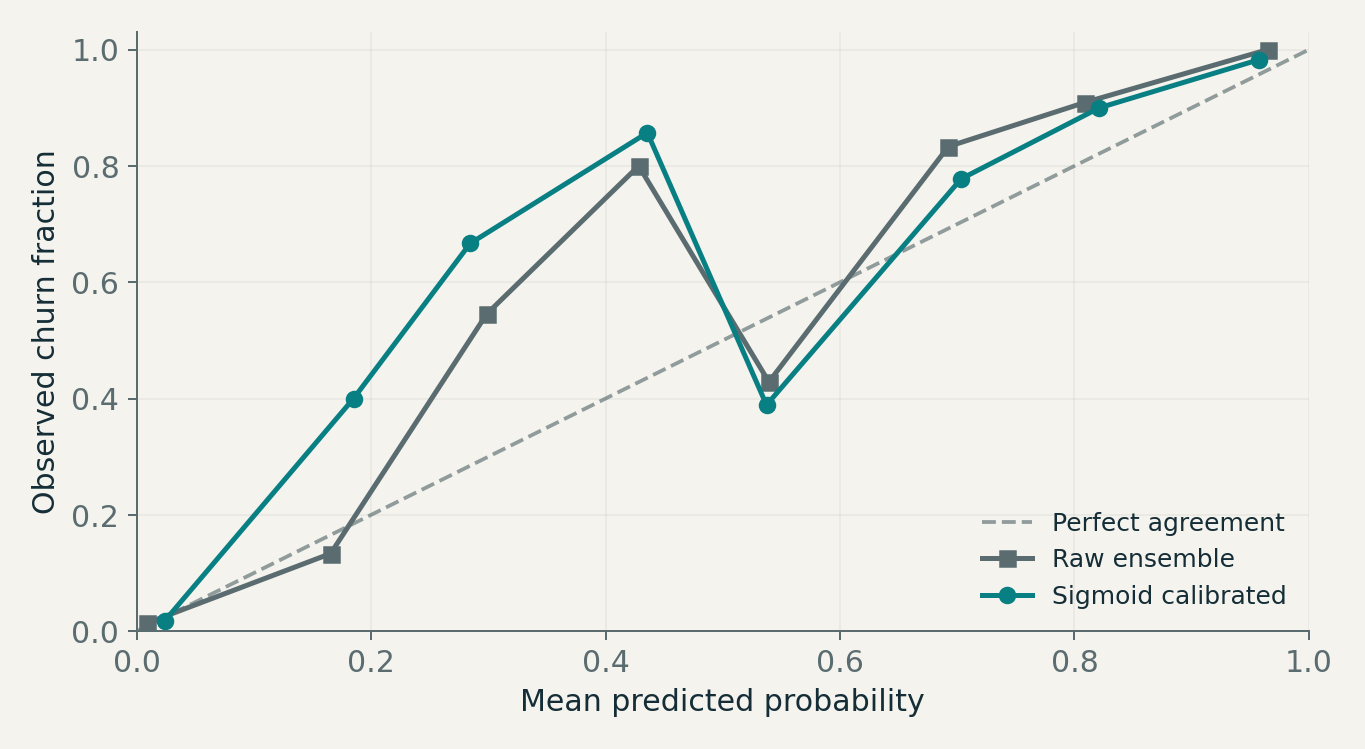

,variant,bin,n,mean_probability,observed_fraction
0,Raw ensemble,0,508,0.008831,0.013780
1,Raw ensemble,1,15,0.165386,0.133333
2,Raw ensemble,2,11,0.298589,0.545455
3,Raw ensemble,3,10,0.428219,0.800000
4,Raw ensemble,4,21,0.539316,0.428571
5,Raw ensemble,5,12,0.692456,0.833333
6,Raw ensemble,6,11,0.808823,0.909091
7,Raw ensemble,7,51,0.964834,1.000000
8,Sigmoid calibrated,0,523,0.023660,0.017208
9,Sigmoid calibrated,1,5,0.184937,0.400000


In [6]:
display(pd.DataFrame({'raw': result['matched_uncalibrated_test_metrics'][selected],
                      'sigmoid': result['test_metrics'][selected]}))
display(Image(filename=str(HERE / 'figures/03_reliability.png')))
display(pd.read_csv(HERE / 'figures/03_reliability.csv'))

## 6. Translate ranking into a capacity question

At 10% requested capacity, round up to 64 of 639 records. The queue contains 63 of 103 churn labels. Ties are broken independently of labels. This is retrospective label concentration, not prevented churn. False-positive/false-negative costs in the report are hypothetical normalized classification penalties, not dollars or offer ROI.

{'reviewed': 64, 'churn_labels': 63, 'recall': np.float64(0.6116504854368932), 'precision': 0.984375}


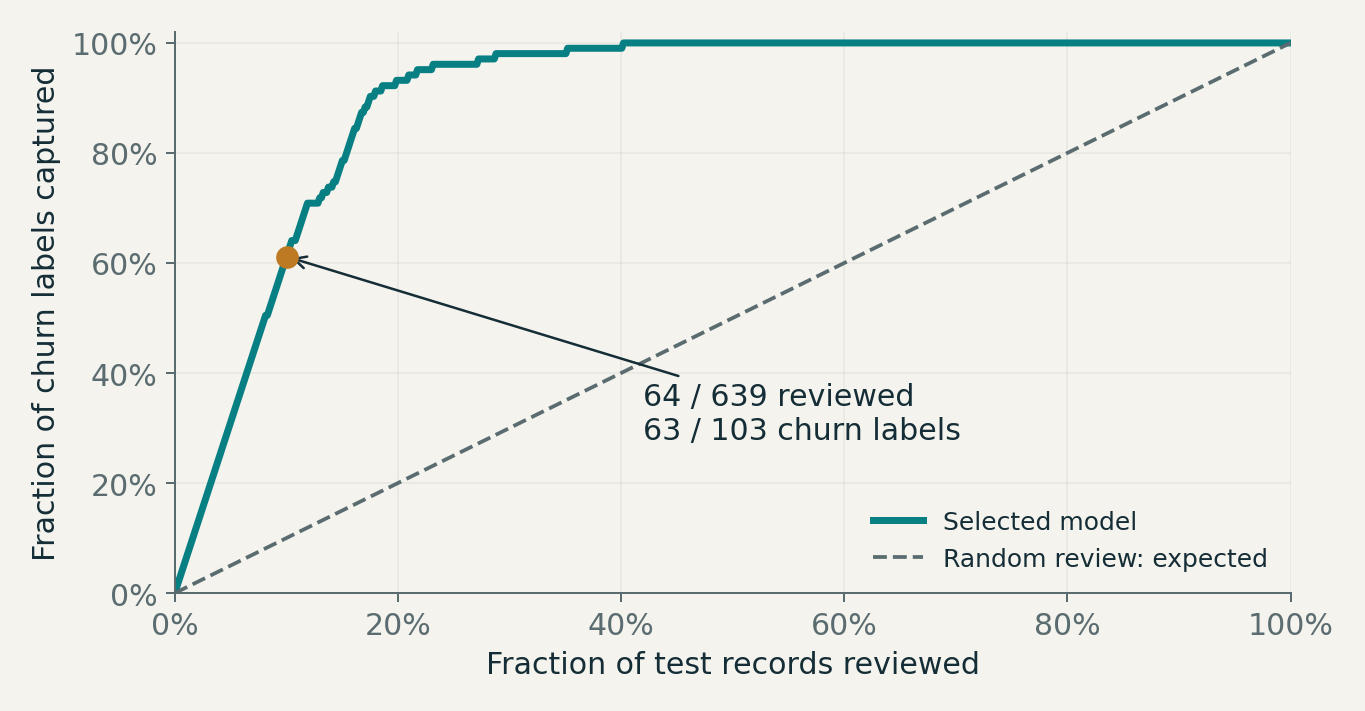

,false_positive_cost,false_negative_cost,development_selected_threshold,test_false_positives,test_false_negatives,test_normalized_cost,units
0,1,5,0.07,31,8,71,Hypothetical normalized classification-cost un...
1,1,10,0.07,31,8,111,Hypothetical normalized classification-cost un...
2,1,20,0.04,45,5,145,Hypothetical normalized classification-cost un...


In [7]:
from study import rank_indices
queue = rank_indices(pred[selected].to_numpy(), pred.row_id.to_numpy())[:int(np.ceil(.10 * len(pred)))]
positives = int(pred.iloc[queue].target.sum())
print({'reviewed': len(queue), 'churn_labels': positives,
       'recall': positives / pred.target.sum(), 'precision': positives / len(queue)})
display(Image(filename=str(HERE / 'figures/04_review_capacity.png')))
display(pd.DataFrame(result['hypothetical_cost_scenarios']))

## 7. Ask where the result could fail

The full-field sensitivity is not an eligible primary candidate. Sparse subgroup evidence cannot establish fairness or reliable benefit. Age groups 1 and 5 have 0 and 1 churn labels; tariff plan 2 has only two. Unknown dependence, unavailable timestamps and one historical source limit the interpretation even when a benchmark score is high.

Primary AP: 0.9298342270339264
All-field sensitivity AP: 0.9415390593187147


,field,value,n,churn_labels,observed_prevalence,mean_probability,brier,adequate_support_for_comparison
0,age_group,1,22,0,0.000000,0.020504,0.000421,False
1,age_group,2,228,40,0.175439,0.165977,0.041579,True
2,age_group,3,266,44,0.165414,0.163281,0.043504,True
3,age_group,4,89,18,0.202247,0.182479,0.019598,True
4,age_group,5,34,1,0.029412,0.020396,0.028592,False
5,tariff_plan,1,585,101,0.172650,0.165026,0.039804,True
6,tariff_plan,2,54,2,0.037037,0.039266,0.009115,False


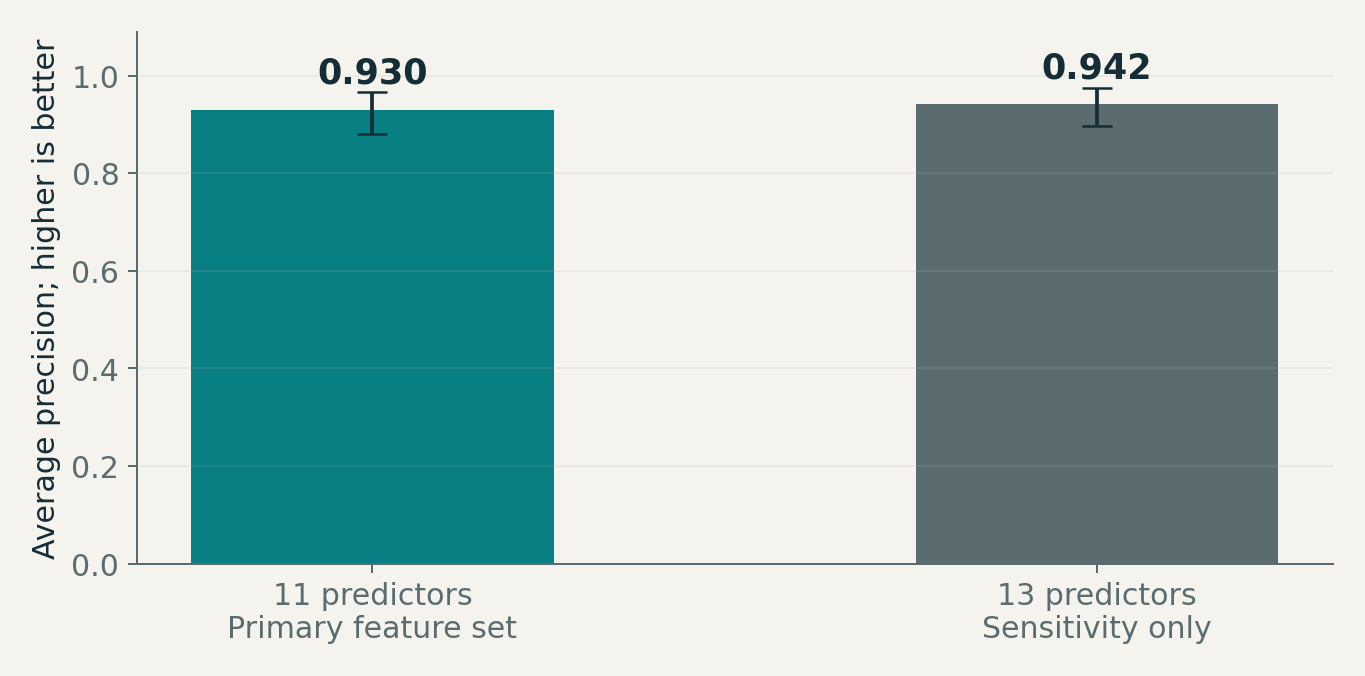

In [8]:
display(pd.DataFrame(result['error_slices']))
display(Image(filename=str(HERE / 'figures/05_feature_sensitivity.png')))
print('Primary AP:', result['test_metrics'][selected]['average_precision'])
print('All-field sensitivity AP:', result['test_metrics']['all_gradient_boosting']['average_precision'])

## 8. A product decision with an evidence requirement

The ranking merits prospective target-domain validation, not immediate retention deployment. Verify feature construction and timing; obtain genuine dated, permitted target-domain records; freeze a review policy; track probability error and capacity capture under current prevalence. A separate randomized intervention is needed to estimate incremental retained customers and net benefit.

**Learning:** ranking, probability quality and causal impact are separate questions. Calibration is a hypothesis to test, not a guaranteed improvement.

**Ownership exercise:** compare raw versus sigmoid calibration using development-only outer folds, preserving the original holdout. Save a new protocol, measured comparison and uncertainty explanation. Do not tune repeatedly against this already-inspected test set.

Next project: forecasting real dated telecom complaint volumes using rolling backtests. Public findings remain findings of their source population, with no employer-data or impact claim.